In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

df = pd.read_csv("heart.csv")

df.head()

,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,target
0,52,1,0,125,212,0,1,168,0,1.0,2,2,3,0
1,53,1,0,140,203,1,0,155,1,3.1,0,0,3,0
2,70,1,0,145,174,0,1,125,1,2.6,0,0,3,0
3,61,1,0,148,203,0,1,161,0,0.0,2,1,3,0
4,62,0,0,138,294,1,1,106,0,1.9,1,3,2,0


In [2]:
print("Dataset Shape:", df.shape)

print("\nColumns:")
print(df.columns.tolist())

print("\nMissing Values:")
print(df.isnull().sum())

print("\nDuplicate Rows:", df.duplicated().sum())

Dataset Shape: (1025, 14)

Columns:
['age', 'sex', 'cp', 'trestbps', 'chol', 'fbs', 'restecg', 'thalach', 'exang', 'oldpeak', 'slope', 'ca', 'thal', 'target']

Missing Values:
age         0
sex         0
cp          0
trestbps    0
chol        0
fbs         0
restecg     0
thalach     0
exang       0
oldpeak     0
slope       0
ca          0
thal        0
target      0
dtype: int64

Duplicate Rows: 723


In [3]:
df = df.drop_duplicates().reset_index(drop=True)

print("Shape after removing duplicates:", df.shape)
print("Duplicate Rows:", df.duplicated().sum())

Shape after removing duplicates: (302, 14)
Duplicate Rows: 0


In [4]:
X = df.drop("target", axis=1)
y = df["target"]

print("Features shape:", X.shape)
print("Target shape:", y.shape)

print("\nTarget distribution:")
print(y.value_counts())

Features shape: (302, 13)
Target shape: (302,)

Target distribution:
target
1    164
0    138
Name: count, dtype: int64


In [5]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training set:", X_train.shape)
print("Testing set:", X_test.shape)

Training set: (241, 13)
Testing set: (61, 13)


In [6]:
from sklearn.tree import DecisionTreeClassifier

decision_tree = DecisionTreeClassifier(random_state=42)
decision_tree.fit(X_train, y_train)

print("Decision Tree model trained successfully.")

Decision Tree model trained successfully.


In [7]:
from sklearn.metrics import accuracy_score

y_pred_tree = decision_tree.predict(X_test)

tree_accuracy = accuracy_score(y_test, y_pred_tree)

print("Decision Tree Accuracy:", tree_accuracy)

Decision Tree Accuracy: 0.8032786885245902


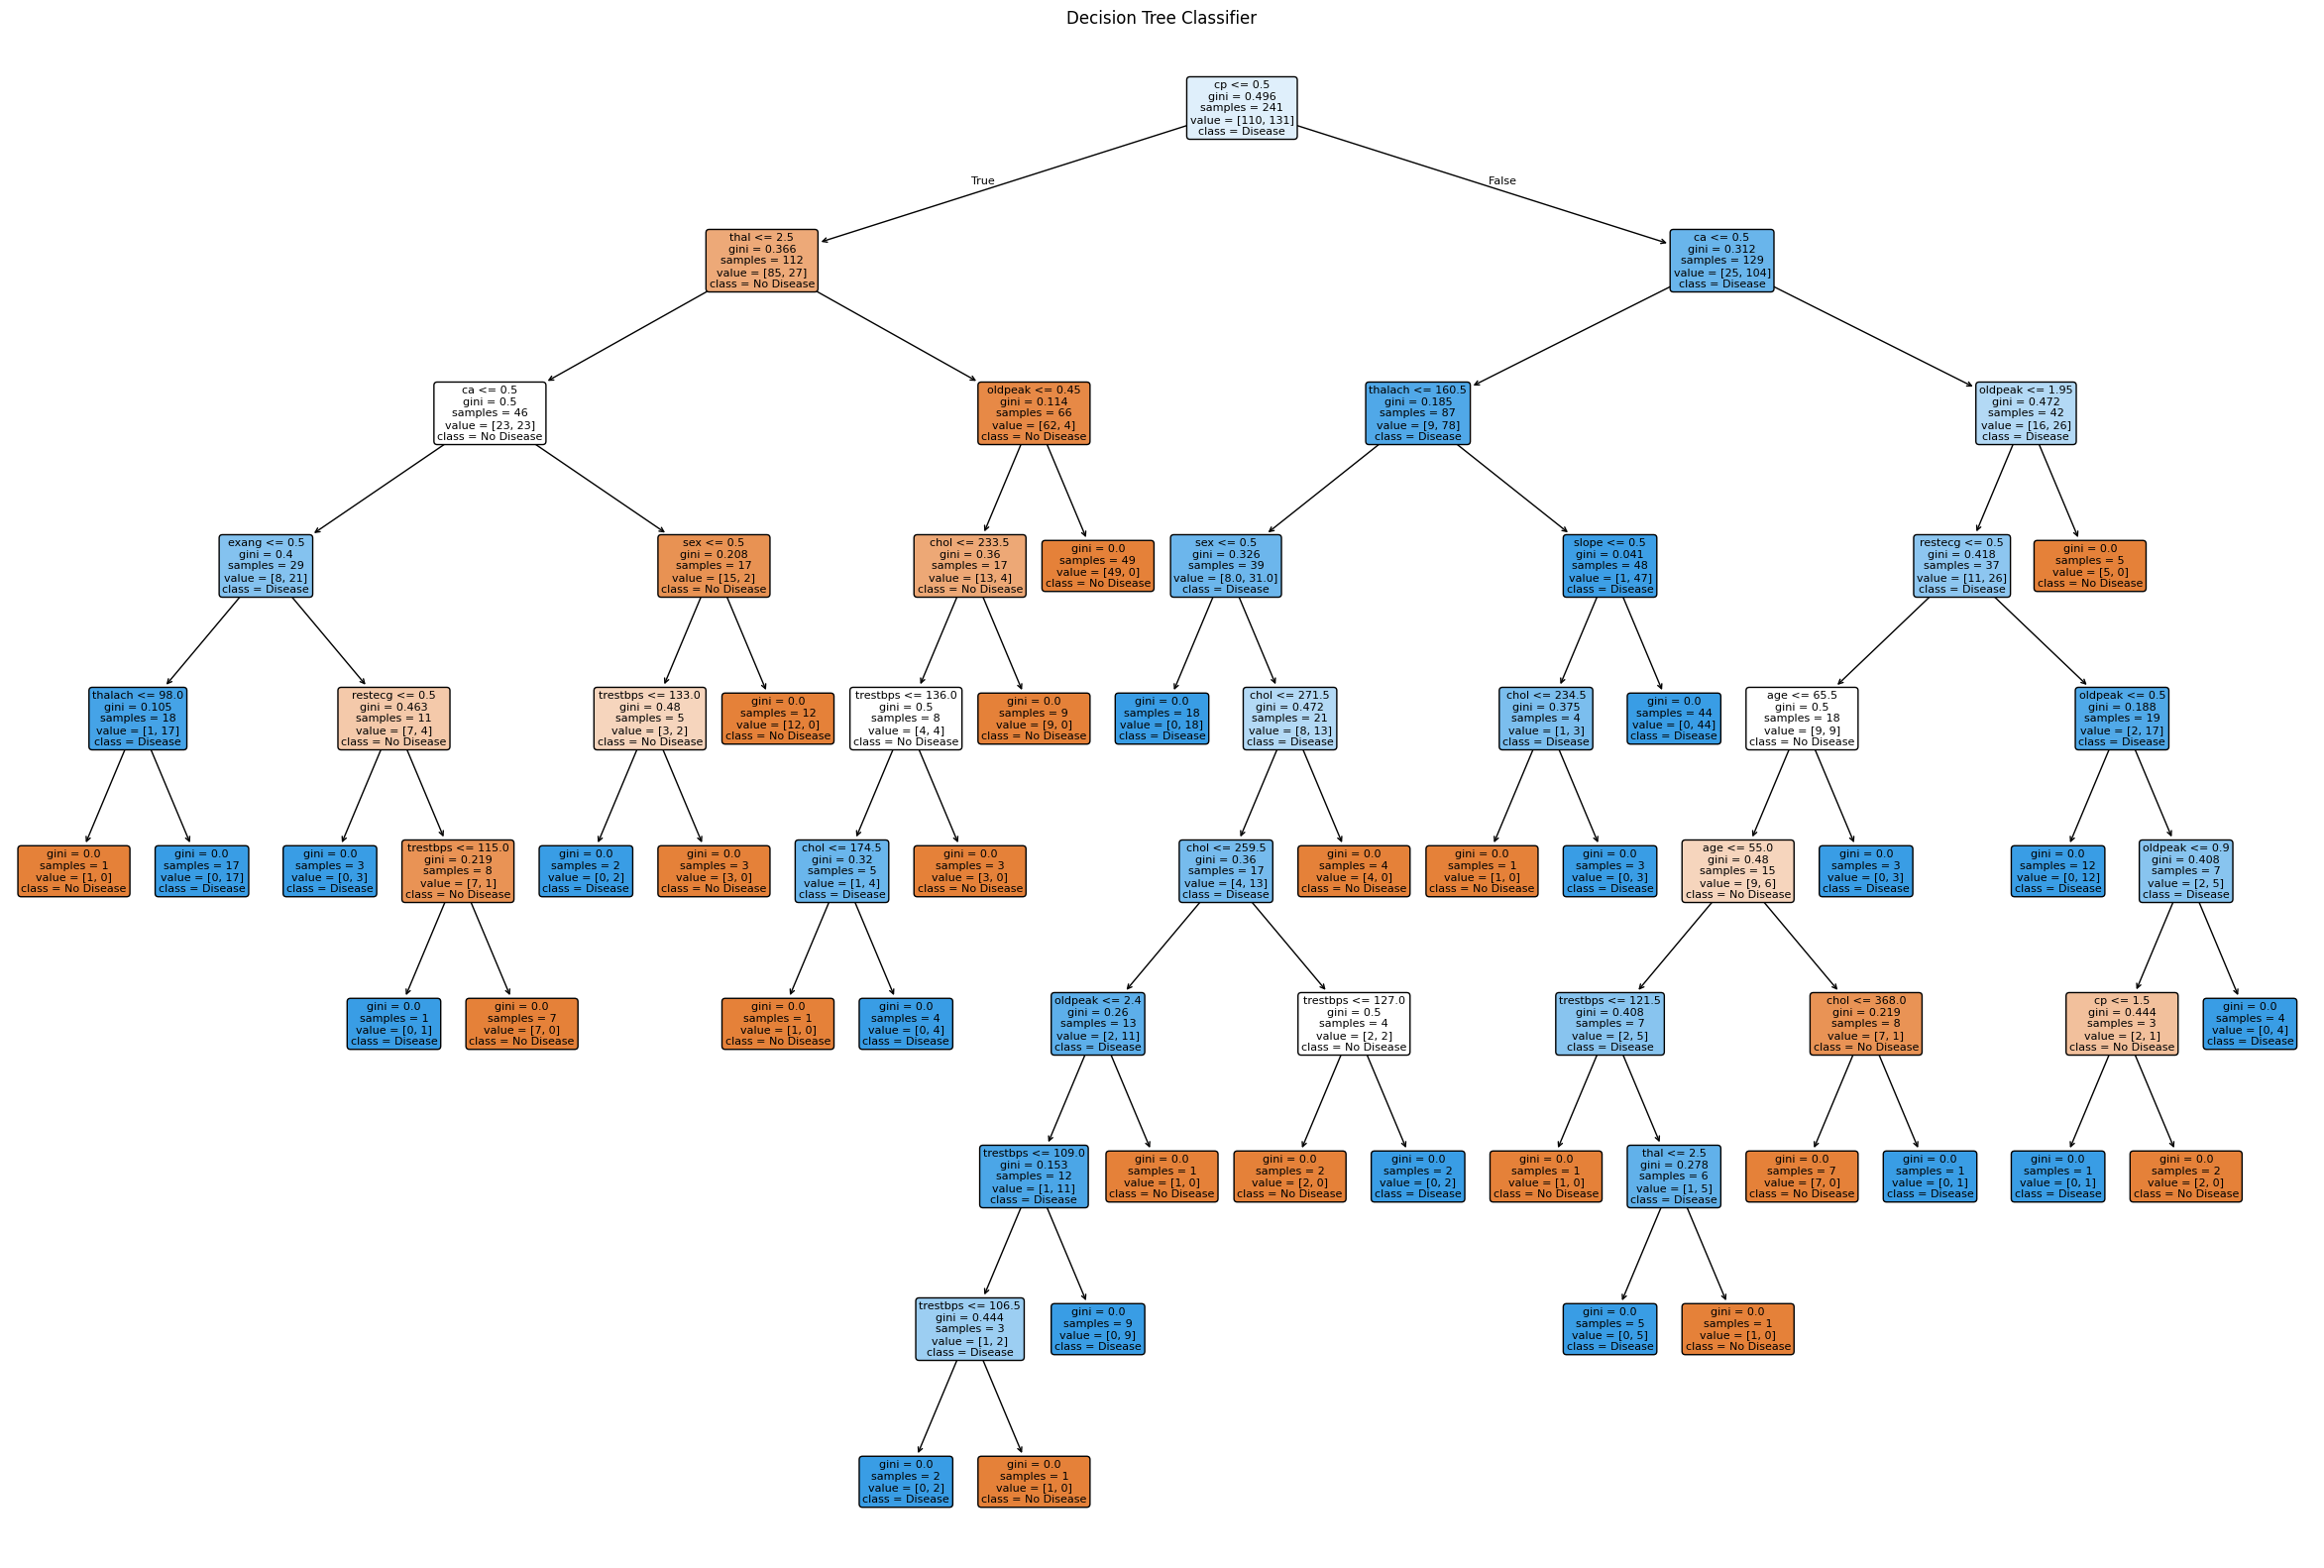

In [8]:
from sklearn.tree import plot_tree

plt.figure(figsize=(30, 20))

plot_tree(
    decision_tree,
    feature_names=X.columns,
    class_names=["No Disease", "Disease"],
    filled=True,
    rounded=True,
    fontsize=8
)

plt.title("Decision Tree Classifier")
plt.show()

In [9]:
depths = [1, 2, 3, 4, 5, 6, 7, 8, 10, None]

train_accuracies = []
test_accuracies = []

for depth in depths:
    model = DecisionTreeClassifier(
        max_depth=depth,
        random_state=42
    )
    
    model.fit(X_train, y_train)
    
    train_pred = model.predict(X_train)
    test_pred = model.predict(X_test)
    
    train_accuracies.append(accuracy_score(y_train, train_pred))
    test_accuracies.append(accuracy_score(y_test, test_pred))

print("Depth | Training Accuracy | Testing Accuracy")
print("-" * 45)

for depth, train_acc, test_acc in zip(
    depths, train_accuracies, test_accuracies
):
    print(f"{str(depth):>5} | {train_acc:.3f}             | {test_acc:.3f}")

Depth | Training Accuracy | Testing Accuracy
---------------------------------------------
    1 | 0.784             | 0.656
    2 | 0.784             | 0.656
    3 | 0.859             | 0.803
    4 | 0.871             | 0.721
    5 | 0.942             | 0.770
    6 | 0.963             | 0.770
    7 | 0.979             | 0.770
    8 | 0.996             | 0.787
   10 | 1.000             | 0.803
 None | 1.000             | 0.803


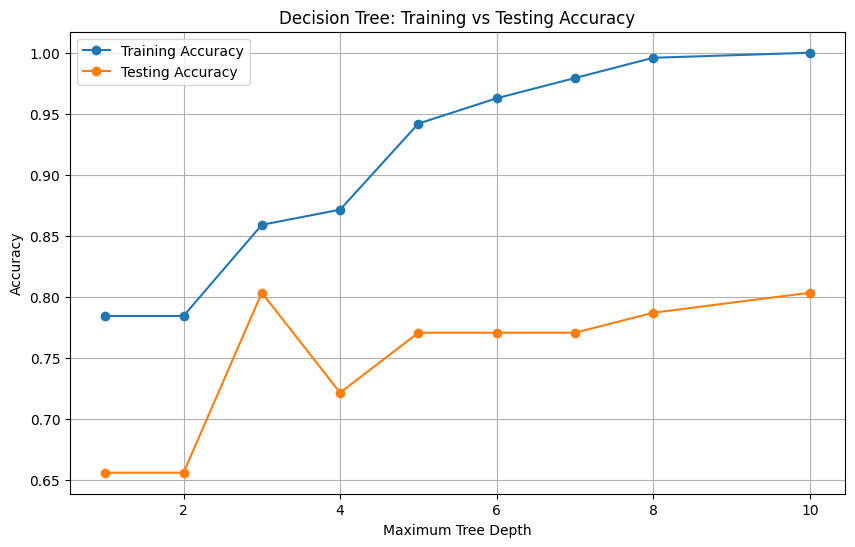

In [10]:
plt.figure(figsize=(10, 6))

plt.plot(depths[:-1], train_accuracies[:-1], marker="o", label="Training Accuracy")
plt.plot(depths[:-1], test_accuracies[:-1], marker="o", label="Testing Accuracy")

plt.xlabel("Maximum Tree Depth")
plt.ylabel("Accuracy")
plt.title("Decision Tree: Training vs Testing Accuracy")
plt.legend()
plt.grid()
plt.show()

In [11]:
# Controlled Decision Tree with max_depth = 3

decision_tree_depth3 = DecisionTreeClassifier(
    max_depth=3,
    random_state=42
)

decision_tree_depth3.fit(X_train, y_train)

y_pred_depth3 = decision_tree_depth3.predict(X_test)

depth3_accuracy = accuracy_score(y_test, y_pred_depth3)

print("Decision Tree Accuracy (max_depth=3):", depth3_accuracy)

Decision Tree Accuracy (max_depth=3): 0.8032786885245902


In [12]:
from sklearn.ensemble import RandomForestClassifier

random_forest = RandomForestClassifier(
    n_estimators=100,
    random_state=42
)

random_forest.fit(X_train, y_train)

y_pred_rf = random_forest.predict(X_test)

rf_accuracy = accuracy_score(y_test, y_pred_rf)

print("Random Forest Accuracy:", rf_accuracy)

Random Forest Accuracy: 0.7540983606557377


In [13]:
feature_importance = pd.Series(
    random_forest.feature_importances_,
    index=X.columns
).sort_values(ascending=False)

print("Feature Importance:")
print(feature_importance)

Feature Importance:
cp          0.173969
thalach     0.131634
ca          0.105700
oldpeak     0.096577
thal        0.090418
age         0.083049
exang       0.073679
trestbps    0.072088
chol        0.067384
sex         0.040229
slope       0.029811
restecg     0.024301
fbs         0.011161
dtype: float64


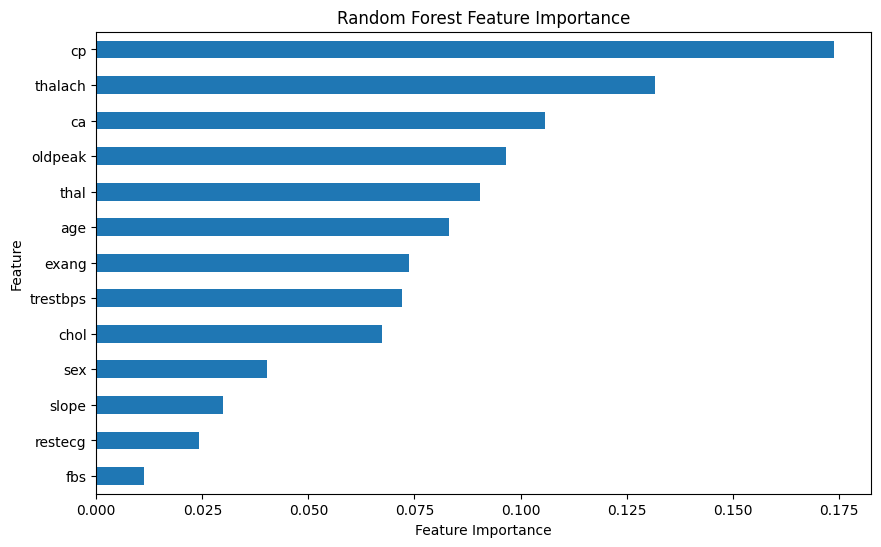

In [14]:
plt.figure(figsize=(10, 6))

feature_importance.sort_values().plot(kind="barh")

plt.xlabel("Feature Importance")
plt.ylabel("Feature")
plt.title("Random Forest Feature Importance")
plt.show()

In [15]:
from sklearn.model_selection import cross_val_score

cv_scores = cross_val_score(
    decision_tree_depth3,
    X,
    y,
    cv=5,
    scoring="accuracy"
)

print("Cross-Validation Scores:")
print(cv_scores)

print("\nMean Cross-Validation Accuracy:", cv_scores.mean())
print("Standard Deviation:", cv_scores.std())

Cross-Validation Scores:
[0.80327869 0.81967213 0.9        0.68333333 0.76666667]

Mean Cross-Validation Accuracy: 0.7945901639344262
Standard Deviation: 0.07067337990115888
